# Análise de Risco à Inundação

In [2]:
from rasterio.mask import mask
from rasterio.warp import reproject, Resampling
from shapely.geometry import box

import geopandas as gpd
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
import rasterio
import os

## Métodos auxiliares

In [3]:
def comparar_mapas(raster_paths, titulos, colors="RdYlGn_r", vmax=4):
    """
    Método para comparar rasters plotando lado a lado.

    Args:
        raster_paths (array): caminhos do arquivos rasters
        titulos (array): titulos das imagens
        colors (str): escala de cores a ser usada
        vmax (int): valor máximo na escala gráfica
    """
    n = len(raster_paths)
    fig, axes = plt.subplots(1, n, figsize=(6*n, 6))
    
    if n == 1:
        axes = [axes]
    
    for ax, path, titulo in zip(axes, raster_paths, titulos):
        with rasterio.open(path) as src:
            raster = np.ma.masked_invalid(src.read(1))
        
        img = ax.imshow(raster, cmap=colors, vmin=0, vmax=vmax)
        ax.set_title(titulo, fontsize=12)
        ax.axis("off")
    
    cbar = fig.colorbar(img, ax=axes, orientation="vertical", fraction=0.03, pad=0.04)
    cbar.set_label("Índice de Risco", rotation=90)
    plt.show()


## Leitura dos Rasters para Análise

In [6]:
cidades = ['recife', 'são-lourenço-da-mata']
cidade = cidades[0]

In [7]:
pasta_rasters = '../dados/rasters'
pasta_manchas = '../dados/manchas-inundacao'

with rasterio.open(os.path.join(pasta_rasters, f'uso_do_solo_{cidade}_reclass.tif')) as src1, \
     rasterio.open(os.path.join(pasta_rasters, f'declividade_{cidade}_reclass.tif')) as src2, \
     rasterio.open(os.path.join(pasta_rasters, f'hipsometria_{cidade}_reclass.tif')) as src3, \
     rasterio.open(os.path.join(pasta_rasters, f'fluxo_acumulado_{cidade}_reclass.tif')) as src4, \
     rasterio.open(os.path.join(pasta_rasters, f'distancia_rio_{cidade}_reclass.tif')) as src5:

    uso = src1.read(1)
    decliv = src2.read(1)
    hipso = src3.read(1)
    fluxo = src4.read(1)
    dist_rios = src5.read(1)

    print(f"Dimensão Uso: {src1.width} x {src1.height}")
    print(f"Dimensão Decl: {src2.width} x {src2.height}")
    print(f"Dimensão Hipso: {src3.width} x {src3.height}")
    print(f"Dimensão Flux: {src4.width} x {src4.height}")
    print(f"Dimensão Dist: {src5.width} x {src5.height}")

    perfil = src1.profile.copy()

caminho_mancha_tif = os.path.join(pasta_manchas, 'mancha_recife.tif')

with rasterio.open(caminho_mancha_tif) as src_mancha:
    mancha_matriz = src_mancha.read(1)

    print(f"Dimensão Mancha: {src_mancha.width} x {src_mancha.height}")

Dimensão Uso: 646 x 898
Dimensão Decl: 646 x 898
Dimensão Hipso: 646 x 898
Dimensão Flux: 646 x 898
Dimensão Dist: 646 x 898
Dimensão Mancha: 646 x 898


In [14]:
# Seleciona apenas pixels válidos e dentro da mancha (y > 0)
mask_mancha = (mancha_matriz > 0) & (~np.isnan(mancha_matriz))

## Otimização por Particle Swarm Optimization (PSO)

In [10]:
# FUNÇÃO OBJETIVO

def funcao_objetivo(pesos):
    pesos = np.array(pesos)
    pesos = pesos / np.sum(pesos)
    w1, w2, w3, w4, w5 = pesos

    mapa = (w1 * uso) + (w2 * hipso) + (w3 * decliv) + (w4 * fluxo) + (w5 * dist_rios)
    
    # Compara a soma ponderada diretamente com os valores PONDERADOS reais da mancha
    # (Em vez do valor fixo 4.0)
    rmse_mancha = np.sqrt(np.nanmean((mapa[mask_mancha] - mancha_matriz[mask_mancha]) ** 2))

    return rmse_mancha

# ALGORITMO PSO

class Particle:
    def __init__(self, x0, bounds):
        self.position = np.array(x0)
        self.velocity = np.random.uniform(-1, 1, len(x0))
        self.pos_best = np.copy(self.position)
        self.err_best = float("inf")
        self.err = float("inf")
        self.bounds = bounds

    def evaluate(self, func):
        self.err = func(self.position)
        if self.err < self.err_best:
            self.err_best = self.err
            self.pos_best = np.copy(self.position)

    def update_velocity(self, global_best):
        w = 0.5
        c1 = 1
        c2 = 2

        r1 = np.random.random(len(self.position))
        r2 = np.random.random(len(self.position))

        cognitive = c1 * r1 * (self.pos_best - self.position)
        social = c2 * r2 * (global_best - self.position)

        self.velocity = w * self.velocity + cognitive + social

    def update_position(self):
        self.position = self.position + self.velocity
        for i in range(len(self.position)):
            self.position[i] = np.clip(self.position[i], self.bounds[i][0], self.bounds[i][1])


class PSO:
    def __init__(self, costFuncion, initial, bounds, n_particles=30, max_iter=80):
        num_dim = len(initial)
        swarm = [Particle(initial, bounds) for _ in range(n_particles)]

        global_best_pos = np.copy(initial)
        global_best_err = float("inf")

        for it in range(max_iter):

            for particle in swarm:
                particle.evaluate(costFuncion)

                if particle.err < global_best_err:
                    global_best_err = particle.err
                    global_best_pos = np.copy(particle.position)

            for particle in swarm:
                particle.update_velocity(global_best_pos)
                particle.update_position()

            print(f"Iteração {it+1}/{max_iter} | Erro = {global_best_err:.6f}")

        print("\n=== RESULTADO FINAL ===")
        print("Melhores pesos:", global_best_pos)
        self.pesos_norm = global_best_pos / np.sum(global_best_pos)
        print("Melhores pesos (normalizados):", self.pesos_norm)
        print("Erro:", global_best_err)

initial = [0.20, 0.20, 0.20, 0.20, 0.20]
bounds = [(0.05, 1)] * 5

otimizacao = PSO(funcao_objetivo, initial, bounds, n_particles=30, max_iter=20)
peso_uso, peso_hipso, peso_decliv, peso_fluxo, peso_dist = otimizacao.pesos_norm

Iteração 1/20 | Erro = 1.240038
Iteração 2/20 | Erro = 1.029021
Iteração 3/20 | Erro = 1.026299
Iteração 4/20 | Erro = 1.025929
Iteração 5/20 | Erro = 1.025682
Iteração 6/20 | Erro = 1.025682
Iteração 7/20 | Erro = 1.025682
Iteração 8/20 | Erro = 1.025682
Iteração 9/20 | Erro = 1.025650
Iteração 10/20 | Erro = 1.025650
Iteração 11/20 | Erro = 1.025650
Iteração 12/20 | Erro = 1.025649
Iteração 13/20 | Erro = 1.025647
Iteração 14/20 | Erro = 1.025646
Iteração 15/20 | Erro = 1.025646
Iteração 16/20 | Erro = 1.025646
Iteração 17/20 | Erro = 1.025646
Iteração 18/20 | Erro = 1.025646
Iteração 19/20 | Erro = 1.025646
Iteração 20/20 | Erro = 1.025646

=== RESULTADO FINAL ===
Melhores pesos: [0.05       0.63350144 1.         0.05       0.30306374]
Melhores pesos (normalizados): [0.02455114 0.31106367 0.49102283 0.02455114 0.14881121]
Erro: 1.0256458329933023


### Pesos encontrados

In [11]:
print("=== IMPORTÂNCIA DAS VARIÁVEIS (PSO) ===")
print(f'Uso do solo: {peso_uso:.3f}')
print(f'Hipsometria: {peso_hipso:.3f}')
print(f'Declividade: {peso_decliv:.3f}')
print(f'Fluxo Acumulado: {peso_fluxo:.3f}')
print(f'Distância do Rio: {peso_dist:.3f}')

=== IMPORTÂNCIA DAS VARIÁVEIS (PSO) ===
Uso do solo: 0.025
Hipsometria: 0.311
Declividade: 0.491
Fluxo Acumulado: 0.025
Distância do Rio: 0.149


### Salvando mapa de risco resultante

In [12]:
risco_pso_path = f'../dados/rasters/risco_alagamento_pso_{cidade}.tif'

risco = (uso * peso_uso) + (hipso * peso_hipso) + (decliv * peso_decliv) + (fluxo * peso_fluxo) + (dist_rios * peso_dist) 
# risco[mask_fora_recife] = np.nan

perfil.update(dtype=rasterio.float32, count=1, nodata=np.nan)

with rasterio.open(risco_pso_path, "w", **perfil) as dst:
    dst.write(risco.astype(rasterio.float32), 1)

print("Mapa de risco salvo em:", risco_pso_path)

Mapa de risco salvo em: ../dados/rasters/risco_alagamento_pso_recife.tif


### Comparando resultados do AHP com o PSO

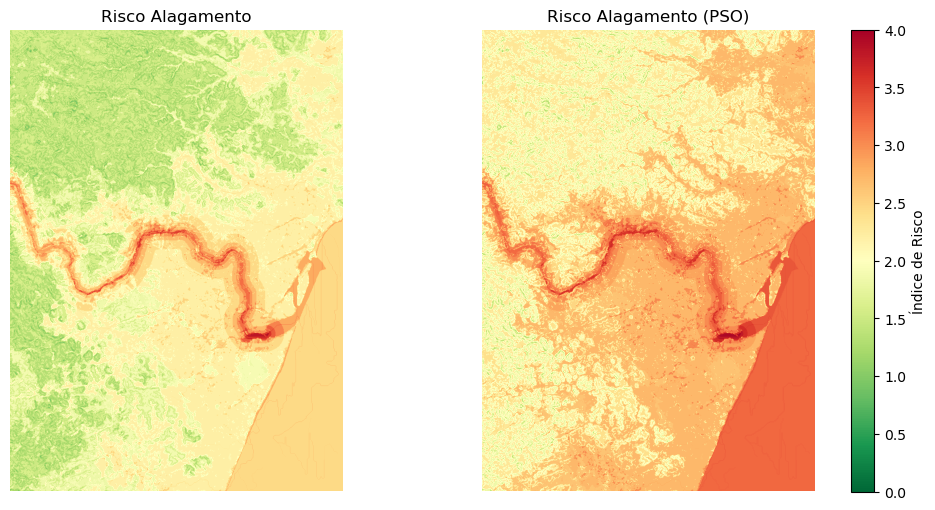

In [19]:
risco_path = f'../dados/rasters/risco_alagamento_{cidade}.tif'
risco_pso_path = f'../dados/rasters/risco_alagamento_pso_{cidade}.tif'

comparar_mapas(
    [risco_path, risco_pso_path],
    ["Risco Alagamento", "Risco Alagamento (PSO)"]
)

## Predição com Random Forest

In [16]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

X_mancha = np.column_stack([
    uso[mask_mancha],
    hipso[mask_mancha],
    decliv[mask_mancha],
    fluxo[mask_mancha],
    dist_rios[mask_mancha]
])

y_mancha = mancha_matriz[mask_mancha]

# Treinamento do Modelo de Regressão
rf_mancha = RandomForestRegressor(
    n_estimators=150,
    max_depth=10,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)
rf_mancha.fit(X_mancha, y_mancha)

# Extração dos Pesos (Importância das Variáveis)
nomes_camadas = ['Uso do solo', 'Hipsometria', 'Declividade', 'Fluxo Acumulado', 'Distância do Rio']
importancias = rf_mancha.feature_importances_

print("=== IMPORTÂNCIA DAS VARIÁVEIS (RANDOM FOREST) ===")
for nome, imp in zip(nomes_camadas, importancias):
    print(f"{nome}: {imp:.3f}")

# Avaliação do ajuste dentro da área alagada
y_pred_mancha = rf_mancha.predict(X_mancha)
print(f"\nDesempenho dentro da mancha:")
print(f"R² (Coeficiente de Determinação): {r2_score(y_mancha, y_pred_mancha):.4f}")
print(f"RMSE (Erro Quadrático Médio): {np.sqrt(mean_squared_error(y_mancha, y_pred_mancha)):.4f}")

=== IMPORTÂNCIA DAS VARIÁVEIS (RANDOM FOREST) ===
Uso do solo: 0.181
Hipsometria: 0.221
Declividade: 0.088
Fluxo Acumulado: 0.023
Distância do Rio: 0.486

Desempenho dentro da mancha:
R² (Coeficiente de Determinação): 0.1636
RMSE (Erro Quadrático Médio): 0.9794


### Criando o mapa de risco

In [21]:
# Predição para o município inteiro
shape_original = uso.shape
mask_validos_mapa = ~np.isnan(uso) & ~np.isnan(hipso) & ~np.isnan(decliv) & ~np.isnan(fluxo) & ~np.isnan(dist_rios)

X_full = np.column_stack([
    uso[mask_validos_mapa],
    hipso[mask_validos_mapa],
    decliv[mask_validos_mapa],
    fluxo[mask_validos_mapa],
    dist_rios[mask_validos_mapa]
])

# Aplica o modelo treinado na área total do município
mapa_risco_rf = np.full(shape_original, np.nan, dtype=np.float32)
mapa_risco_rf[mask_validos_mapa] = rf_mancha.predict(X_full)

# Salva raster final
risco_rf_path = f'../dados/rasters/risco_alagamento_rf_{cidade}.tif'
perfil.update(dtype=rasterio.float32, count=1, nodata=np.nan)

with rasterio.open(risco_rf_path, "w", **perfil) as dst:
    dst.write(mapa_risco_rf, 1)

print(f"\nMapa de risco espacial salvo em: {risco_rf_path}")


Mapa de risco espacial salvo em: ../dados/rasters/risco_alagamento_rf_recife.tif


### Comparando resultados do AHP com o Random Forest

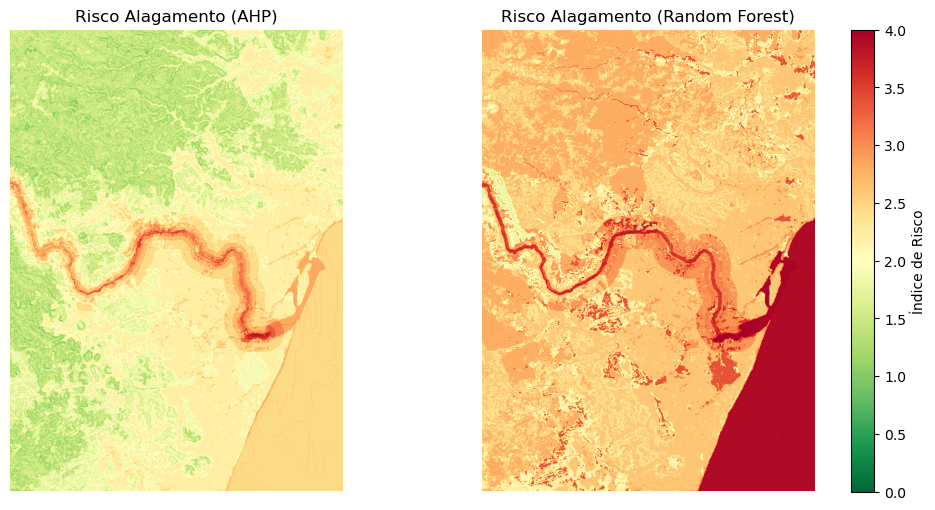

In [22]:
comparar_mapas(
    [risco_path, risco_rf_path],
    ["Risco Alagamento (AHP)", "Risco Alagamento (Random Forest)"]
)